# FILLED REFERENCE — every cell implemented

Not the recording notebook. The take uses `jpeg_quality_study.ipynb`, where the written cells are
empty. This one runs end to end so the output can be compared against expectation.


# Quality setting vs fidelity in the DCT codec

Scope: the transform-and-quantisation stage only. No entropy coding, no chroma subsampling. This is not a
JPEG encoder.

Session plan: state the fidelity target, audit the metric the code prints, prove the transform is exact,
prove the corrected metric, sweep both images, document the settings that behave invalidly, then decide.

Cells marked WRITE IT are empty on purpose. Helper cells are pre-built plumbing, not findings.


In [1]:
import importlib.util, numpy as np, matplotlib.pyplot as plt
np.set_printoptions(precision=2, suppress=True, linewidth=160)


## 1. The existing implementation

The basis, the transform and the quantisation table come from `DCT.py` in this repository, unmodified.

In [2]:
spec = importlib.util.spec_from_file_location("dctmod", "DCT.py")
dctmod = importlib.util.module_from_spec(spec); spec.loader.exec_module(dctmod)
T = dctmod.dct_coeff(); Tpinv = np.linalg.inv(T)
print("T:", T.shape)


T: (8, 8)


## 2. Image in, reconstruction out (plumbing)

`reconstruct` applies the repository's blockwise transform, quantisation and inverse. Blocks whose size
is not a multiple of eight are left as they were initialised, exactly as the repository does.

In [3]:
def load(path):
    import cv2
    I = cv2.imread(path)
    return I.astype(float)

def reconstruct(img, level):
    Q = dctmod.quantization_level(level)
    out = np.zeros_like(img)
    H, W, _ = img.shape
    for c in range(3):
        ch = img[:, :, c] - 128.0
        with np.errstate(divide="ignore", invalid="ignore"):
            for i in range(H // 8):
                for j in range(W // 8):
                    blk = ch[8*i:8*i+8, 8*j:8*j+8]
                    coef = T @ blk @ Tpinv
                    q = np.round(coef / Q)
                    out[8*i:8*i+8, 8*j:8*j+8, c] = Tpinv @ (q * Q) @ T
    out = np.nan_to_num(out, nan=0.0, posinf=255.0, neginf=0.0) + 128.0
    return np.clip(np.round(out), 0.0, 255.0)   # the stored image is 8-bit   # the stored image is 8-bit, so clip before measuring


In [4]:
def nz_share(img, Q):
    """Share of quantised coefficients that survive, as a percentage, across all blocks and channels."""
    nz = tot = 0
    for c in range(img.shape[2]):
        ch = img[:, :, c] - 128.0
        for i in range(img.shape[0] // 8):
            for j in range(img.shape[1] // 8):
                q = np.round((T @ ch[8*i:8*i+8, 8*j:8*j+8] @ Tpinv) / Q)
                nz += int((q != 0).sum()); tot += 64
    return 100.0 * nz / tot


## 3. The fidelity target

State it before measuring anything. A threshold chosen after seeing results is a rationalisation.

**TARGET: 35 dB peak signal-to-noise ratio against the original image.** Chosen where
blocking stops being visible in an introductory class, and low enough that the knob still has
room to move.


## 4. Test content

Generated deterministically. A block with no high-frequency content cannot show what quantisation removes.

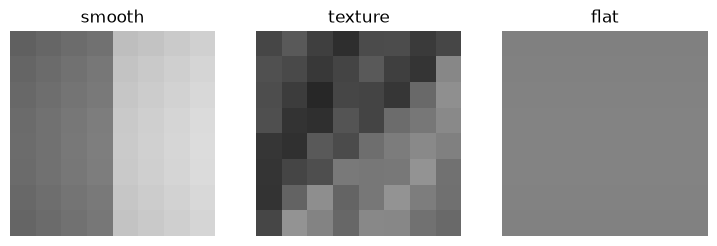

In [5]:
yy, xx = np.mgrid[0:8, 0:8]
smooth = np.clip(96 + 6.0*xx + 70.0*(xx >= 4) + 12.0*np.sin(np.pi*yy/8), 0, 255)
rng = np.random.default_rng(7)
texture = np.clip(70 + 55*(xx + yy >= 8) + 18*np.sin(1.7*xx + 0.9*yy) + rng.normal(0, 8, (8, 8)), 0, 255)
flat = np.clip(np.full((8, 8), 128.0) + 3.0*np.sin(np.pi*yy/8), 0, 255)
blocks = {"smooth": np.round(smooth), "texture": np.round(texture), "flat": np.round(flat)}
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, (k, b) in zip(ax, blocks.items()):
    a.imshow(b, cmap="gray", vmin=0, vmax=255); a.set_title(k); a.axis("off")
plt.show()


## 5. The quality knob

`dctmod.quantization_level(n)` maps a level to an 8x8 step table. Reproduce its rule, then inspect the
extremes.

In [6]:
Q50 = np.array([[16,11,10,16,24,40, 51, 61],
                [12,12,14,19,26,58,60,55],
                [14,13,16,24,40,57,69,56],
                [14,17,22,29,51,87,80,62],
                [18,22,37,56,68,109,103,77],
                [24,35,55,64,81,104,113,92],
                [49,64,78,87,103,121,120,101],
                [72,92,95,98,112,100,103,99]], dtype=float)

def quant_table(q):
    s = (100.0 - q) / 50.0 if q > 50 else 50.0 / q
    return np.minimum(np.round(s * Q50), 255)

print("my rule matches the code's table for level 50:",
      bool(np.array_equal(quant_table(50), dctmod.quantization_level(50))))


my rule matches the code's table for level 50: True


## 6. One block, through the pipeline

The transform is easier to trust when one block's journey is visible: pixels, coefficients, quantised
coefficients, then the reconstruction.


In [7]:
img = load("Image/scene_a.jpg")
print("image:", img.shape)


image: (768, 1408, 3)


In [8]:
blk_i, blk_j = 528, 944          # an 8x8 block on the number plate
blk = img[blk_i:blk_i+8, blk_j:blk_j+8, 0] - 128.0
Q = quant_table(50)
print("the block, shifted by 128:")
print(blk.astype(int))


the block, shifted by 128:
[[-93 -72  46  71  34 -57  56  61]
 [ 14 -49  -2  68   5 -34  68  57]
 [ 83  -3 -29  72 -25  -3  64  53]
 [ 84  -4 -36  68 -40  26  63  55]
 [ 70 -43   5  52 -48  49  62  54]
 [ 39 -67  59  36 -39  38   7  50]
 [-35   2  70  25 -32  42 -29  37]
 [-66  47  64  24 -28  41 -85 -26]]


## 6a. Where the basis comes from

$T$ is not a lookup table. It is the 8-point DCT-II basis, and the 2-D transform applies it separably —
across the rows, then down the columns.

$$C[k,n] \;=\; \alpha(k)\,\cos\!\left(\frac{\pi\,(2n+1)\,k}{16}\right),
\qquad \alpha(0)=\sqrt{\tfrac{1}{8}},\quad \alpha(k)=\sqrt{\tfrac{2}{8}}\ \ \text{for } k>0$$

Forward transform of an 8x8 block $X$: $\;F = T\,X\,T^{\mathsf T}$.

Inverse: $\;X = T^{\mathsf T}F\,T$, which is only valid because $T$ is orthonormal, $T\,T^{\mathsf T}=I$.

Quantisation, the single lossy step: $\;F^{q}_{uv} = \operatorname{round}\!\left(F_{uv}\,/\,Q_{uv}\right)$.


In [9]:
k = np.arange(8)[:, None]; n = np.arange(8)[None, :]
alpha = np.where(k == 0, 1 / np.sqrt(8), np.sqrt(2 / 8))
C = alpha * np.cos(np.pi * (2 * n + 1) * k / 16)
print("basis rebuilt from the formula matches the repo's matrix:", np.allclose(C, T))


basis rebuilt from the formula matches the repo's matrix: True


In [10]:
coef = T @ blk @ Tpinv
print(np.round(coef, 1))


[[ 122.   -72.9   14.   -93.2   48.   133.6   55.9  -60.8]
 [  29.2  -84.1   29.6   -8.4   95.    84.7 -111.1   57.7]
 [ -74.    -1.6 -129.5 -106.1  -47.5  -98.1   -6.1   42.8]
 [  -7.5  -66.   -28.7  -44.6    5.6   29.9   49.3   57.7]
 [ -13.5   -3.8  -27.4   -4.2  -20.5  -15.9  -17.9  -13.6]
 [   4.5   -8.8   -3.6  -20.4   -4.8  -18.3   -7.3   -4. ]
 [  -6.2   15.5   -8.1   -1.5    5.6    2.4   10.5    4.6]
 [   8.5   -5.1    3.1   -2.1  -11.1   -1.9   -5.5   -3.5]]


In [11]:
q = np.round(coef / Q)
print(q.astype(int))
print("surviving coordinates:", int((q != 0).sum()), "of 64")


[[ 8 -7  1 -6  2  3  1 -1]
 [ 2 -7  2  0  4  1 -2  1]
 [-5  0 -8 -4 -1 -2  0  1]
 [-1 -4 -1 -2  0  0  1  1]
 [-1  0 -1  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0]]
surviving coordinates: 29 of 64


In [12]:
back = Tpinv @ (q * Q) @ T
print("largest pixel error in this block:", round(float(np.abs(back - blk).max()), 1), "grey levels")


largest pixel error in this block: 25.3 grey levels


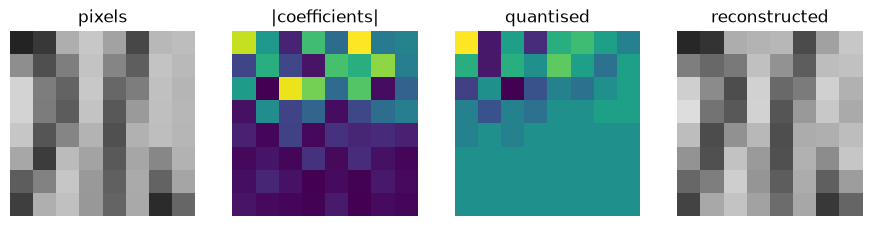

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(11, 3))
ax[0].imshow(blk + 128, cmap="gray", vmin=0, vmax=255); ax[0].set_title("pixels")
ax[1].imshow(np.abs(coef), cmap="viridis"); ax[1].set_title("|coefficients|")
ax[2].imshow(q, cmap="viridis"); ax[2].set_title("quantised")
ax[3].imshow(back + 128, cmap="gray", vmin=0, vmax=255); ax[3].set_title("reconstructed")
for a in ax: a.axis("off")
plt.show()


## 7. Measure the fidelity — RMSE and PSNR at this setting

Two numbers, computed on the reconstruction against the original. RMSE is in grey levels of a 0 to 255
range; PSNR expresses that error against the peak, in decibels, so it is comparable across images.


In [14]:
mid = reconstruct(img, 50)
print("reconstruction error present:", not np.allclose(img, mid))


reconstruction error present: True


In [15]:
def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

def psnr(a, b):
    mse = float(np.mean((a - b) ** 2))
    return float("inf") if mse == 0 else float(10 * np.log10(255 ** 2 / mse))

print("RMSE", round(rmse(img, mid), 4), "grey levels | PSNR", round(psnr(img, mid), 2), "dB")


RMSE 3.7723 grey levels | PSNR 36.6 dB


## 8. The transform itself is innocent

In [16]:
print("max |T @ T.T - I| =", float(np.abs(T @ T.T - np.eye(8)).max()))


max |T @ T.T - I| = 6.661338147750939e-16


In [17]:
blk = img[:8, :8, 0] - 128.0
print("round-trip max abs error =", float(np.abs(Tpinv @ (T @ blk @ Tpinv) @ T - blk).max()))


round-trip max abs error = 1.7763568394002505e-14


## 9. Sweep the knob — image A

In [18]:
LEVELS = [90, 70, 50, 40, 30, 20, 10]
rows = []
for lvl in LEVELS:
    Q = quant_table(lvl); rec = reconstruct(img, lvl)
    rows.append((lvl, Q.min(), Q.max(), nz_share(img, Q), rmse(img, rec), psnr(img, rec),
                 float(np.abs(img - rec).max())))
    print(f"{lvl:3d} steps {rows[-1][1]:5.0f}-{rows[-1][2]:3.0f} surviving {rows[-1][3]:5.1f}%"
          f" RMSE {rows[-1][4]:6.2f} PSNR {rows[-1][5]:5.2f} max {rows[-1][6]:5.0f}")


 90 steps     2- 24 surviving  26.7% RMSE   1.79 PSNR 43.07 max    21


 70 steps     6- 73 surviving  15.8% RMSE   2.97 PSNR 38.67 max    42


 50 steps    10-121 surviving  11.9% RMSE   3.77 PSNR 36.60 max    70


 40 steps    12-151 surviving  10.4% RMSE   4.18 PSNR 35.71 max    71


 30 steps    17-202 surviving   8.7% RMSE   4.76 PSNR 34.58 max    87


 20 steps    25-255 surviving   6.6% RMSE   5.73 PSNR 32.97 max   100


 10 steps    50-255 surviving   3.9% RMSE   7.91 PSNR 30.17 max   122


## 10. Reproduce on image B

In [19]:
img2 = load("Image/scene_b.jpg")
rows2 = []
for lvl in LEVELS:
    Q = quant_table(lvl); rec = reconstruct(img2, lvl)
    rows2.append((lvl, Q.min(), Q.max(), nz_share(img2, Q), rmse(img2, rec), psnr(img2, rec),
                  float(np.abs(img2 - rec).max())))
    print(f"{lvl:3d} PSNR {rows2[-1][5]:5.2f} max {rows2[-1][6]:5.0f}")


 90 PSNR 53.69 max    21


 70 PSNR 48.15 max    44


 50 PSNR 45.95 max    57


 40 PSNR 44.53 max    61


 30 PSNR 42.87 max    67


 20 PSNR 41.01 max    73


 10 PSNR 37.36 max    93


## 11. Settings whose behaviour is invalid

Document these rather than reporting them as results.

In [20]:
Q100 = quant_table(100)
print("level 100 table: min", Q100.min(), "max", Q100.max(), "| all zeros:", bool((Q100 == 0).all()))


level 100 table: min 0.0 max 0.0 | all zeros: True


In [21]:
clipped = [q for q in range(1, 101) if (quant_table(q) == 255).any()]
print("levels whose table hits the 255 ceiling:", min(clipped), "to", max(clipped),
      "| first unaffected level:", max(clipped) + 1)


levels whose table hits the 255 ceiling: 1 to 23 | first unaffected level: 24


In [22]:
crop = img[:765, :1021]
rc = reconstruct(crop, 90)
print("edge column mean", round(float(rc[:, -1].mean()), 1),
      "| edge row mean", round(float(rc[-1, :].mean()), 1),
      "| interior mean", round(float(rc[:760, :1016].mean()), 1))


edge column mean

 128.0 | edge row mean 128.0 | interior mean 109.7


## Comparison table

| level | step min-max | non-zero coeffs | RMSE | PSNR (dB) | max abs error | meets target |
|---|---|---|---|---|---|---|
| | | | | | | |


## Decision and teaching conclusion

_Unfinished: the target, the lowest setting that holds it on the harder image, where the error concentrates,
and what that setting costs visually._

**Decision (filled reference):** teach with **level 70**, the lowest setting on this grid that holds 35 dB on
both images. scene_a is the binding case: 34.58 dB at level 30 misses, 35.71 dB at level 40 clears. scene_b is far easier
throughout, which is the point — size does not predict difficulty.

**Conclusion:** the transform is exact, so the loss is the table. Fidelity falls steeply from 90 to 70 and then
flattens, so the knob is non-linear and a single quality number means nothing without the curve.


In [23]:
print(f"{'level':>5} {'steps':>10} {'surv':>7} {'RMSE':>6} {'PSNR':>6} {'max':>4}")
for lvl, lo, hi, nzp, e, p, mx in rows:
    print(f"{lvl:5d} {lo:4.0f}-{hi:4.0f} {nzp:6.1f}% {e:6.2f} {p:6.2f} {mx:4.0f}")
print()
print("scene_b (1408x768), same settings:")
for lvl, lo, hi, nzp, e, p, mx in rows2:
    print(f"{lvl:5d} {lo:4.0f}-{hi:4.0f} {nzp:6.1f}% {e:6.2f} {p:6.2f} {mx:4.0f}")


level      steps    surv   RMSE   PSNR  max
   90    2-  24   26.7%   1.79  43.07   21
   70    6-  73   15.8%   2.97  38.67   42
   50   10- 121   11.9%   3.77  36.60   70
   40   12- 151   10.4%   4.18  35.71   71
   30   17- 202    8.7%   4.76  34.58   87
   20   25- 255    6.6%   5.73  32.97  100
   10   50- 255    3.9%   7.91  30.17  122

scene_b (1408x768), same settings:
   90    2-  24    3.7%   0.53  53.69   21
   70    6-  73    2.4%   1.00  48.15   44
   50   10- 121    2.1%   1.29  45.95   57
   40   12- 151    2.0%   1.51  44.53   61
   30   17- 202    1.9%   1.83  42.87   67
   20   25- 255    1.8%   2.27  41.01   73
   10   50- 255    1.7%   3.46  37.36   93
